In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi

In [3]:
# neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
prefix = '/mnt/staging/' # or 
figure_config_root = str(PREPARES / "config") + "/"
fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"
figure_config_root = str(PREPARES / "config") + "/"

In [4]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
# palatte_dict['LV'] = '#ee8c7d'
# palatte_dict['tail'] = 'palegreen'
palatte_dict['LT'] = '#b3b3b3'
palatte_dict['RT']  = '#e4c494' ##b69d76 back up


In [5]:
new_cmap = load_pickle(figure_config_root+'sunset_cmap')

# spatial heterogeneity (awake rest)

In [74]:
load_path = str(PREPARES / "heterogeneity/all-seed") + "/"
load_contour_path = str(PREPARES / "heterogeneity-contours") + "/"

bdp_w_order = ['LFP','RFP','LHP','RHP','LM','RM','LW','RW','LN','RN','LV','RV','LT','RT']
mice_list = ['cm125','cm128','cm193']
corr_maps_dict={}; M2_ind_dict={};node_coords_dict={};
clean_contours_M2_dict={};M2_homunculus_dict={};
clean_contours_S1_dict={};S1_homunculus_dict={};
clean_contours_fit={};clean_contours_S1_dict={};M2_homunculus_fit={}
mask_dict = {};
for mouse in mice_list:
    corr_maps_dict[mouse]={}
    clean_contours_M2_dict[mouse] = load_pickle(load_contour_path+'clean_contours_'+mouse)
    M2_homunculus_dict[mouse] = load_pickle(load_contour_path+'dict_M2_full_'+mouse)

    clean_contours_fit[mouse] = load_pickle(load_contour_path+'clean_contours_fit_'+mouse)
    M2_homunculus_fit[mouse] = load_pickle(load_contour_path+'dict_fit_result_M2_'+mouse)
    
    clean_contours_S1_dict[mouse] = load_pickle(load_contour_path+'clean_contours_S1_'+mouse)
    S1_homunculus_dict[mouse] = load_pickle(load_contour_path+'dict_S1_full_'+mouse)

    dict_save = load_pickle(load_contour_path+'dict_save_'+mouse)
    M2_ind = dict_save['M2_ind']
    M2_ind_dict[mouse] = M2_ind
    
    
    with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:
        IDX_sorted = np.array(f_idx['IDX_sorted']).T
        IDX_sorted = IDX_sorted.astype(float)
        IDX_sorted[IDX_sorted==0]='nan'
        num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
        props = regionprops(IDX_sorted.astype(int))
        node_coords = [props[i].centroid for i in range(len(props))]
        node_coords = np.asarray(node_coords, dtype=np.float32)
        
        mask = IDX_sorted >0
        mask = mask.astype(float)
        mask[mask==0]='nan'
        
    node_coords_dict[mouse] = node_coords
    mask_dict[mouse]=mask
    

    with h5py.File(load_path+mouse+'_all_corr_maps_dict.h5', 'r') as hf:
        for i in range(len(bdp_w_order)):
            bdp=bdp_w_order[i]
            region_number = M2_ind[bdp]
            try:
                corr_maps_dict[mouse][bdp+'-M2'] = np.array(hf['roi_'+str(region_number)])
            except:
                try:
                    corr_maps_dict[mouse][bdp+'-M2'] = np.array(hf['roi-'+str(region_number)])
                except:
                    corr_maps_dict[mouse][bdp+'-M2'] = np.array(hf['roi_roi_'+str(region_number)])
                


**hetereoneity**

In [75]:
def contour_to_roi(image,contour):
    import scipy.ndimage as ndimage  
    r = mask
    # Create an empty image to store the masked array
    r_mask = np.zeros_like(r, dtype='bool')
    # r_mask[:]=np.nan

    # Create a contour image by using the contour coordinates rounded to their nearest integer value
    r_mask[np.round(contour[:, 0]).astype('int'), np.round(contour[:, 1]).astype('int')] = 1

    # Fill in the hole created by the contour boundary
    r_mask = ndimage.binary_fill_holes(r_mask)

    # Invert the mask since you want pixels outside of the region
    # r_mask = ~r_mask
    
    r_mask = r_mask.astype('float')
    r_mask[r_mask == 0] = np.nan

    return r_mask

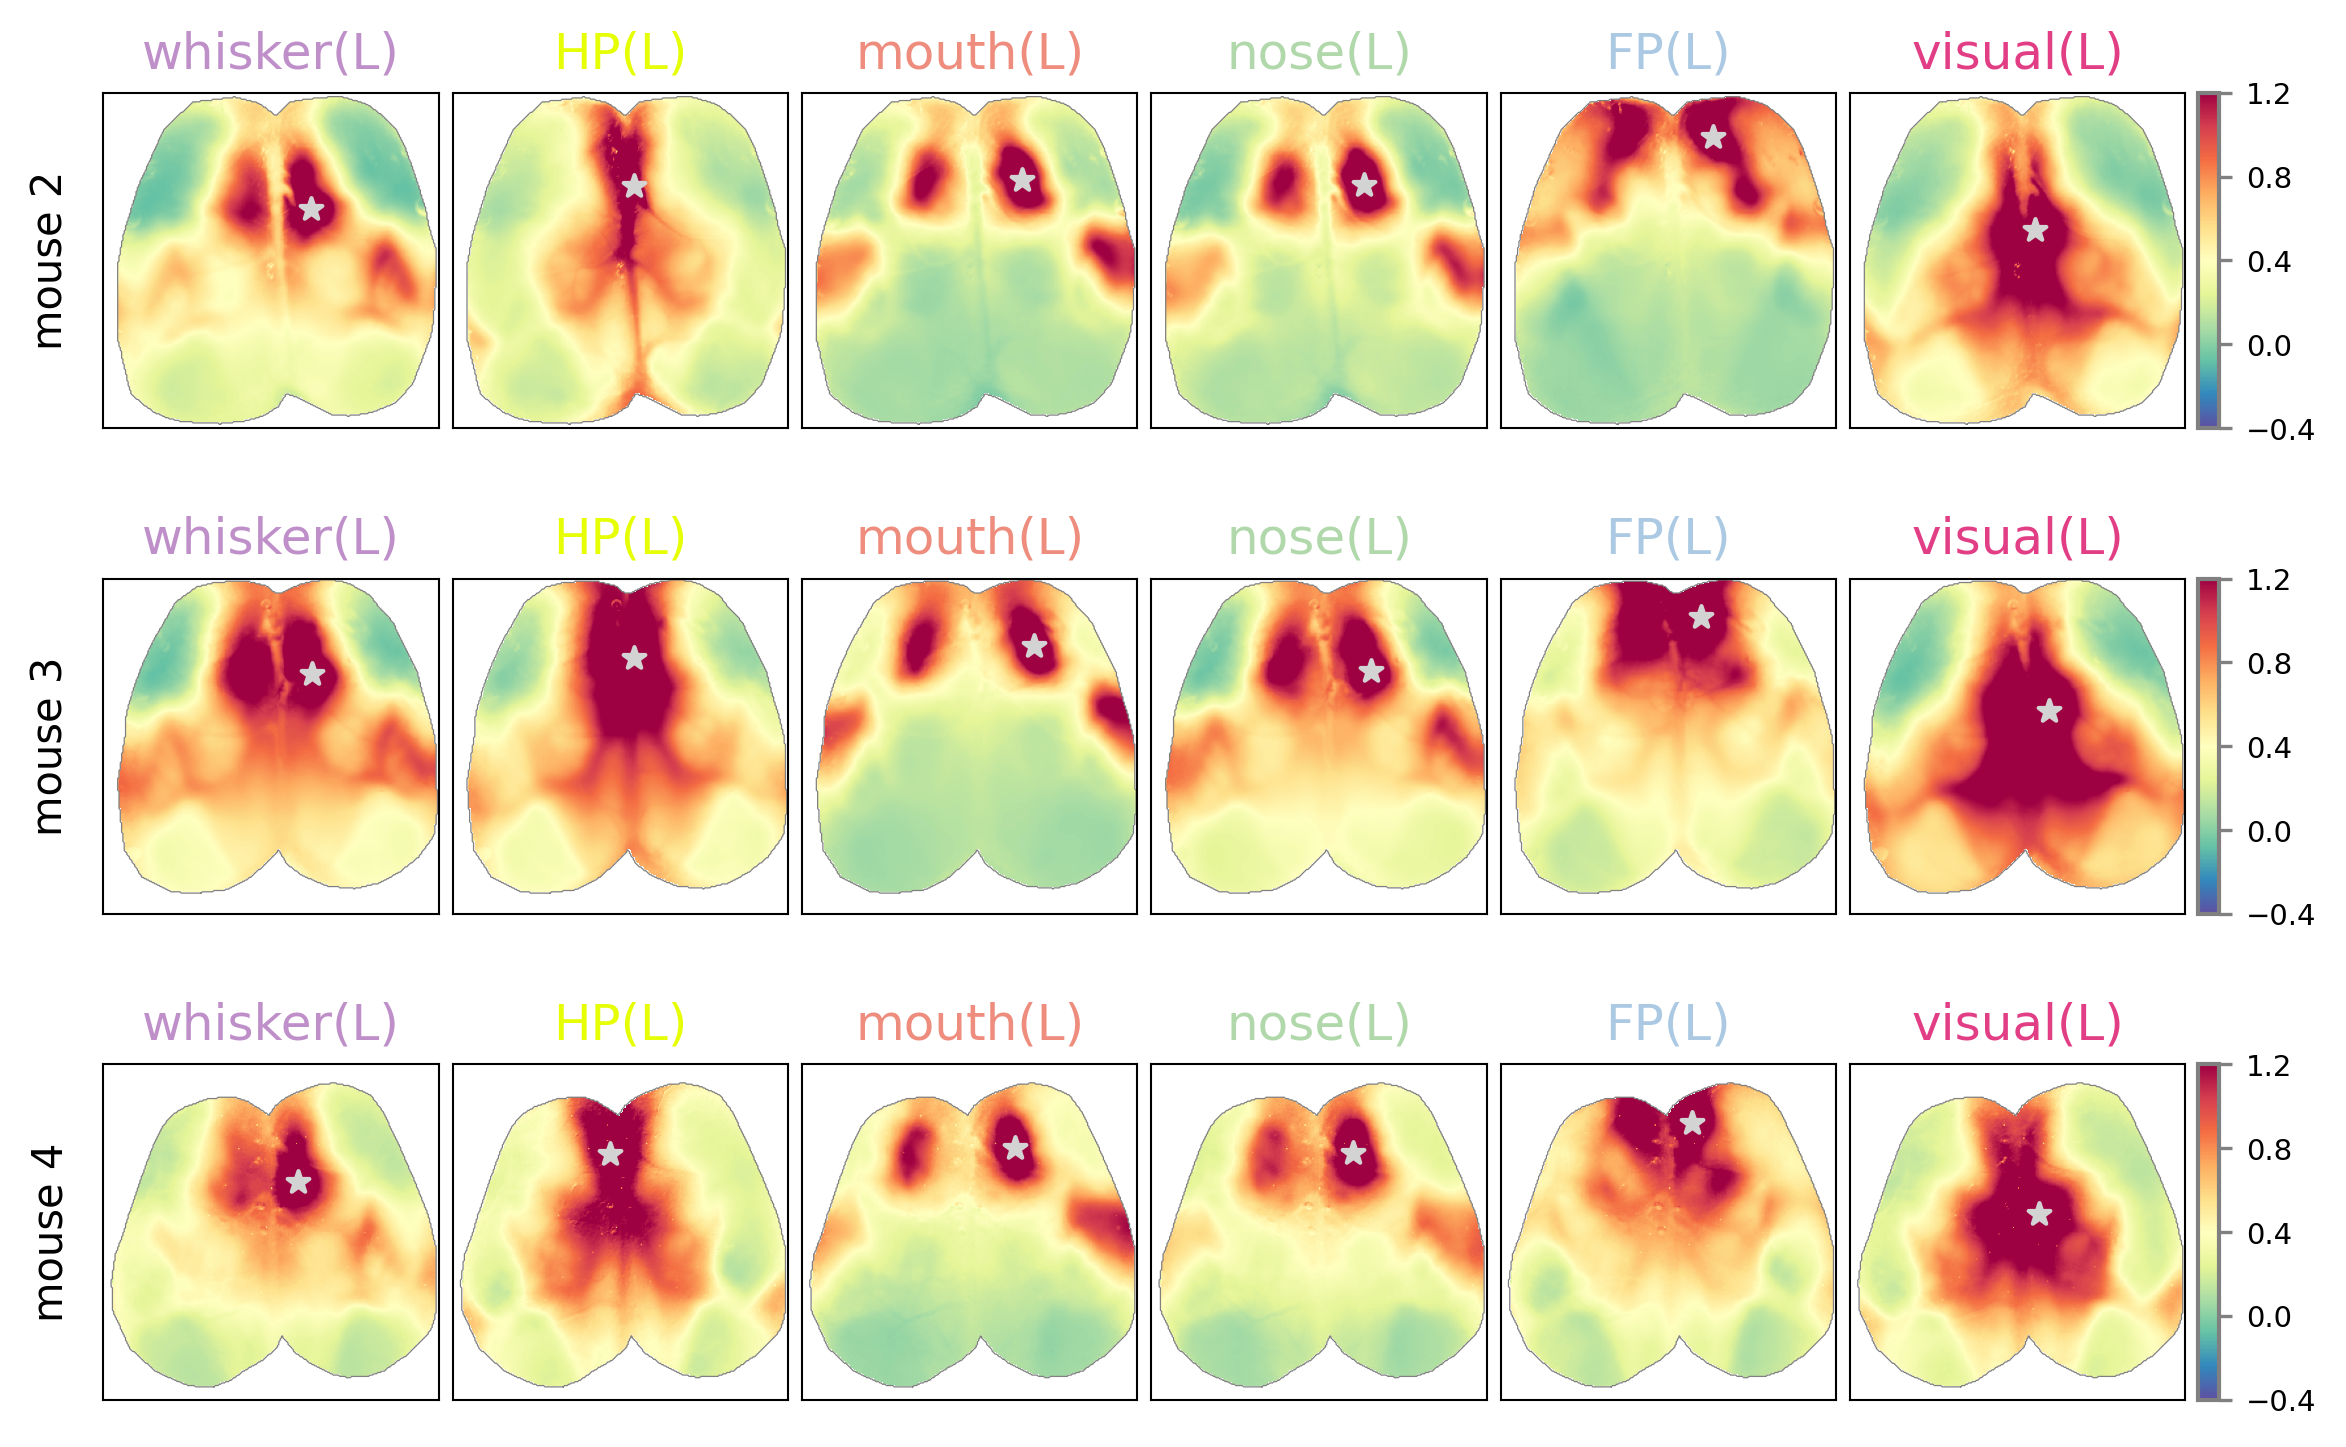

In [77]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)
bdp_short_dict = {'LFP':'FP(L)','LHP':'HP(L)','LM':'mouth(L)','LW':'whisker(L)',
                  'LN':'nose(L)','RFP':'FP(R)','RHP':'HP(R)','RM':'mouth(R)',
                  'RW':'whisker(R)','RN':'nose(R)','LV':'visual(L)','RV':'visual(R)',
                 'RT':'tail(R)','LT':'tail(L)'}
# --- Define layout parameters ---
bdp_w_order = ['LW', 'LHP', 'LM', 'LN', 'LFP', 'LV']
x_offset = 2
y_offset = 2
x_gap = 0
y_gap = 2       # vertical space between mice (can be adjusted)
x_width = 5
y_height = 5
n_plots_per_mouse = len(bdp_w_order)


# --- Create Subplots and Axes ---
axes_dict = {} # Use a dictionary to store axes instead of exec

for i_mouse, mouse in enumerate(mice_list):
    # CHANGED: Simplified y_base for a single row per mouse
    y_base = y_offset + i_mouse * (y_height + y_gap)

    for i_bdp, bdp in enumerate(bdp_w_order):
        # REMOVED: The concept of multiple rows per mouse is gone
        col = i_bdp
        x_start = x_offset + col * (x_width + x_gap)
        y_start = y_base # All plots in the same row
        y_stop = y_start + y_height

        ax = fig.add_subplot(gs[y_start:y_stop, x_start:x_start + x_width])
        ax.set_xticks([])
        ax.set_yticks([])
        # Store axis in a dictionary for easy access later
        axes_dict[(mouse, bdp)] = ax

    # CHANGED: Colorbar position is now aligned with the single row
    cb_x_start = x_offset + n_plots_per_mouse * (x_width + x_gap)
    cb_width = 1
    cb_ax = fig.add_subplot(
        gs[y_base:y_base + y_height, cb_x_start:cb_x_start + cb_width]
    )
    # Store colorbar axis
    axes_dict[(mouse, 'colorbar')] = cb_ax


# --- Plotting Loop (Minimal changes here, but now uses the dictionary) ---
for i_mouse, mouse in enumerate(mice_list):
    binary_image_filled = corr_maps_dict[mouse]['RFP'+'-M2'] > -100
    brain_contours = measure.find_contours(binary_image_filled, level=0.5)
        
    for i_bdp, bdp in enumerate(bdp_w_order):
        ax = axes_dict[(mouse, bdp)] # Get the correct axis
        
        # Plot the main image
        sbp = ax.imshow(np.arctanh(corr_maps_dict[mouse][bdp+'-M2']), cmap='Spectral_r', vmin=-0.4, vmax=1.2)

        if mouse == 'cm229':
            ax.set_xlim([12, 256]); ax.set_ylim([256, 12]);
        # ... (other mouse-specific limits) ...
        
        ax.set_title(bdp_short_dict[bdp], color=palatte_dict[bdp])
        if i_bdp == 0:
            ax.set_ylabel('mouse ' + str(i_mouse + 2))
            
        # Plot overlays (contours, markers, etc.)
        region_number = M2_ind_dict[mouse][bdp]
        ax.scatter(node_coords_dict[mouse][region_number, 1], node_coords_dict[mouse][region_number, 0], marker='*', s=30, c='lightgray', zorder=2)
        
        # ... (rest of your contour plotting logic) ...
        for contour in brain_contours:
            ax.plot(contour[:, 1], contour[:, 0], linewidth=0.3, color='gray', alpha=1)
        
    # --- Colorbar ---
    cb_ax = axes_dict[(mouse, 'colorbar')] # Get the correct colorbar axis
    cb = fig.colorbar(sbp, cax=cb_ax, ticks=[-0.4, 0, 0.4, 0.8,1.2], orientation='vertical')
    cb.ax.tick_params(labelsize=7, length=3, color='gray')
    cb.ax.yaxis.tick_right()
    cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(1)
    cb_ax.set_aspect(10)
    cb_ax.set_anchor('W')


# --- Final Spine Adjustments ---
for axis in ['top', 'right', 'left', 'bottom']:
    for ax in axes_dict.values():
        ax.spines[axis].set_linewidth(0.5)

plt.savefig('figS5-functional_connectivity_M2.svg', format='svg', dpi=300)


In [11]:
load_path = str(PREPARES / "heterogeneity") + "/"
bdp_w_order = ['LFP','RFP','LHP','RHP','LM','RM','LW','RW']
corr_maps_medetomidine_dict = {}

mice_list = ['cm193','cm229']
for mouse in mice_list:
    corr_maps_medetomidine_dict[mouse]={}

    M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
    sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse)

    with h5py.File(load_path+mouse+'_all_corr_maps_dict_medetomidine.h5', 'r') as hf:
        for i in range(len(bdp_w_order)):
            bdp=bdp_w_order[i]
            region_number = sensory_ind[bdp]
            try:
                corr_maps_medetomidine_dict[mouse][bdp+'-sensory'] = np.array(hf['roi_'+str(region_number)])
            except:
                corr_maps_medetomidine_dict[mouse][bdp+'-sensory'] = np.array(hf['roi_roi_'+str(region_number)])

                

In [ ]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=5
for i_mouse, mouse in enumerate(mice_list):
    for i_bdp ,bdp in enumerate(bdp_w_order):
        x_start = x_offset + i_bdp*5
        y_start = y_offset+i_mouse*5
        y_stop = y_start + 5
        i_ax = 8*i_mouse+i_bdp
        exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_start+5])".format(i_ax))
        exec("ax{}.set_yticks([])".format(i_ax))
        exec("ax{}.set_xticks([])".format(i_ax))
    # add colorbar
    exec("ax99{} = fig.add_subplot(gs[y_start:y_stop,x_start+5:x_start+7])".format(i_mouse))
    # add consolidated M2 map
    # exec("ax00{} = fig.add_subplot(gs[y_start:y_stop,x_start+8:x_start+8+5])".format(i_mouse))
    exec("ax00{}.set_yticks([])".format(i_mouse))
    exec("ax00{}.set_xticks([])".format(i_mouse))    

for i_mouse, mouse in enumerate(mice_list):
    binary_image_filled = corr_maps_medetomidine_dict[mouse]['RFP'+'-sensory']>-100
    brain_contours = measure.find_contours(binary_image_filled, level=0.5)

    for i_bdp ,bdp in enumerate(bdp_w_order):

        divnorm=colors.TwoSlopeNorm(vmin=-0.2, vcenter=0, vmax=1)
        region_number = sensory_ind_dict[mouse][bdp]
        i_ax = 8*i_mouse+i_bdp
        exec("sbp{}=ax{}.imshow(corr_maps_medetomidine_dict[mouse][bdp+'-sensory'],cmap=new_cmap,norm=divnorm)".format(i_mouse,i_ax))

        if mouse =='cm229':
            exec("ax{}.set_xlim([12,256]);ax{}.set_ylim([256,12]);".format(i_ax,i_ax))
        if mouse =='cm284':
            exec("ax{}.set_xlim([14,256]);ax{}.set_ylim([249,7]);".format(i_ax,i_ax))
        if mouse =='cm126':
            exec("ax{}.set_xlim([9,256]);ax{}.set_ylim([256,9]);".format(i_ax,i_ax))
        if mouse =='cm128':
            exec("ax{}.set_xlim([9,256]);ax{}.set_ylim([247,0]);".format(i_ax,i_ax))

        if i_mouse==0:
            exec("title_here = ax{}.set_title(bdp_short_dict[bdp],color=palatte_dict[bdp])".format(i_ax))
        if i_bdp==0:
            exec("ax{}.set_ylabel('mouse '+str(i_mouse+2))".format(i_ax))
        exec("ax{}.scatter(node_coords_dict[mouse][region_number,1], node_coords_dict[mouse][region_number,0], marker='*', s=30, c='lightgray', zorder=2)".format(i_ax))

        for contour in brain_contours:
            exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='gray',alpha=0.9)".format(i_ax))

    exec("cb = fig.colorbar(sbp{}, cax=ax99{},ticks=[-0.1,0,0.4,0.8],fraction=0.5,orientation='vertical');".format(i_mouse,i_mouse))
    cb.ax.tick_params(labelsize=7,length=3,color='gray')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(1)

    exec("ax99{}.set_aspect(10);ax99{}.set_anchor('W')".format(i_mouse,i_mouse))
    # tick_locator = ticker.MaxNLocator(nbins=4)
    # cb.locator = tick_locator
    # cb.update_ticks()

plt.savefig('figS5-all-corr-maps-all-mice-medetomidine.svg',format='svg',dpi=300)

In [12]:
mice_list

['cm193', 'cm229']